# Compare methods and thresholds

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


greedy [(93, 99), (147, 148)]
{'matched_events': 2, 'detected_events': 2, 'true_events': 2, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0}
exhaustive [(0, 21), (39, 67), (84, 109), (138, 159), (174, 195)]
{'matched_events': 2, 'detected_events': 5, 'true_events': 2, 'false_positives': 3, 'missed_events': 0, 'precision': 0.4, 'recall': 1.0}


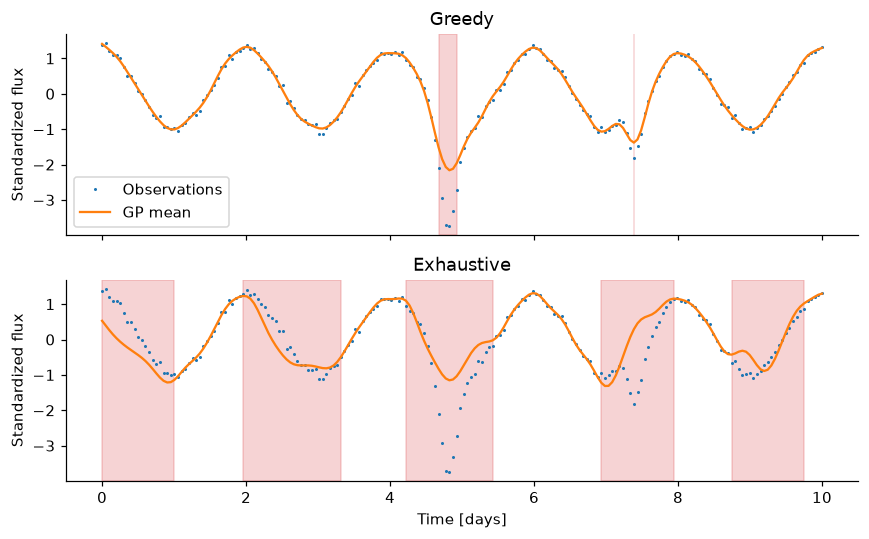

In [2]:
# Generate one reproducible light curve for both searches.
lc = Nahiku.from_synthetic_noise(duration=10, n_points=200, period=2,
                                 amplitude=0.3, white_noise=0.02, red_noise=0, seed=48)

# Inject a symmetric dip and an asymmetric exocomet profile.
lc.inject_anomaly(center=4.8, width=0.12, depth=0.8, shape="gaussian")
lc.inject_anomaly(center=7.4, width=0.07, depth=0.45, shape="exocomet")

# Standardize once and fit the shared baseline model.
lc.standardize()
lc.fit_gp(period=2, length_scale=4, iterations=120)

# Grow negative events from leave-one-out seeds using residual thresholds.
greedy = lc.greedy_search(sigma=4, grow_sigma=2, seed_statistic="loo", growth="threshold",
                         direction="negative", gap_factor=5, max_events=20, backend="numpy")

# Independently score a grid of intervals using the same fitted GP.
exhaustive = lc.exhaustive_search(min_points=3, max_points=16, step=3,
                                size_step=3, threshold=1e-8)

# Compare observations, conditional predictions, and detected intervals.
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, sharey=True)
for ax, result in zip(axes, [greedy, exhaustive]):
    ax.plot(result.time, result.flux, ".", ms=2, label="Observations")
    ax.plot(result.time, result.mean, label="GP mean")
    for a, b in result.intervals:
        ax.axvspan(result.time[a], result.time[b-1], color="C3", alpha=.2)
    ax.set(title=result.method.title(), ylabel="Standardized flux")
axes[0].legend()
axes[-1].set_xlabel("Time [days]")
fig.tight_layout();

# Compare recovery against the injected truth rather than comparing raw scores.
for result in (greedy, exhaustive):
    print(result.method, result.intervals)
    print(lc.evaluate(result))

The upper panel shows the GP prediction conditioned on observations outside all detected intervals. In the lower panel, each colored curve excludes only its own candidate window. Matching dots identify the excluded observations, and bands show ±2 predictive observation standard deviations. By default, each merged event is represented by its strongest selected candidate, with ties resolved by sample bounds. Use `selection="all"` to show all selected windows, including overlaps. A merged event may span several scored windows. Joint scores use correlations between observations as well as the pointwise uncertainties shown in the bands.

`event_index` selects a merged event by its zero-based index and plots its representative candidate's GP across the full light curve. Other detections remain in the conditioning data. The stored predictions include any candidate-specific refits, so plotting requires no further optimization or live GP. Use `kind="residuals"` to inspect residuals after excluding all detected intervals. Numerical exports include the conditional distributions.

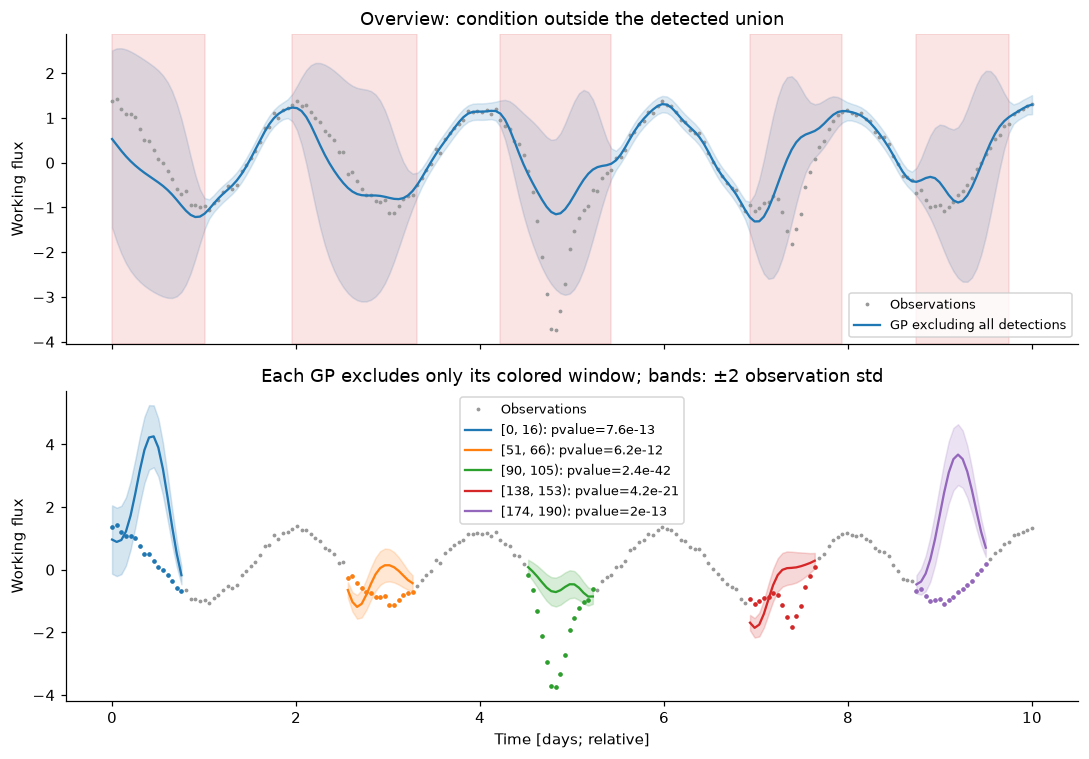

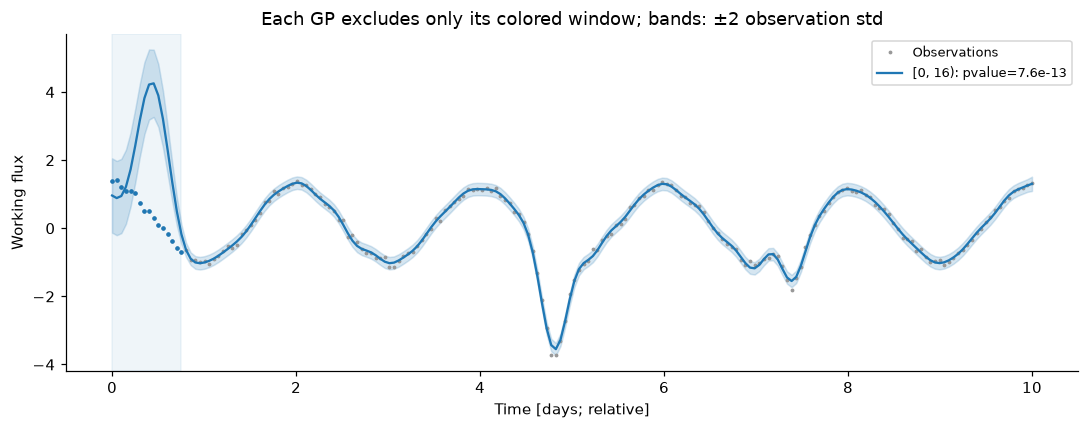

In [3]:
# Inspect the scored conditional fit for one representative window per event.
exhaustive.plot(kind="conditional");

# Plot one candidate's GP over the full light curve, excluding only that window.
if exhaustive.intervals:
    exhaustive.plot(kind="conditional", event_index=0);

# All overlapping selected windows remain accessible with selection="all".
# exhaustive.plot(kind="conditional", selection="all");

## Compare after prewhitening

Remove periodic variability before fitting the GP, while keeping the GP configuration and search thresholds unchanged. The frequency range contains the synthetic baseline frequency of 0.5 cycles/day. Balmung uses all observations, including the injected dips; no truth mask is supplied to preprocessing or detection. A matched injection-free control measures how fitting the sinusoid changes the injected signal.

  0%|          | 0/3 [00:00<?, ?it/s]

 33%|███▎      | 1/3 [00:00<00:00, 260.42it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

 33%|███▎      | 1/3 [00:00<00:00, 335.22it/s]

Removed frequencies [cycles/day]: [0.49662541]
Deepest-sample retained fraction: 0.9561468321911749


greedy [(93, 99), (147, 148)]
{'matched_events': 2, 'detected_events': 2, 'true_events': 2, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0}
exhaustive [(84, 109), (144, 159)]
{'matched_events': 2, 'detected_events': 2, 'true_events': 2, 'false_positives': 0, 'missed_events': 0, 'precision': 1.0, 'recall': 1.0}


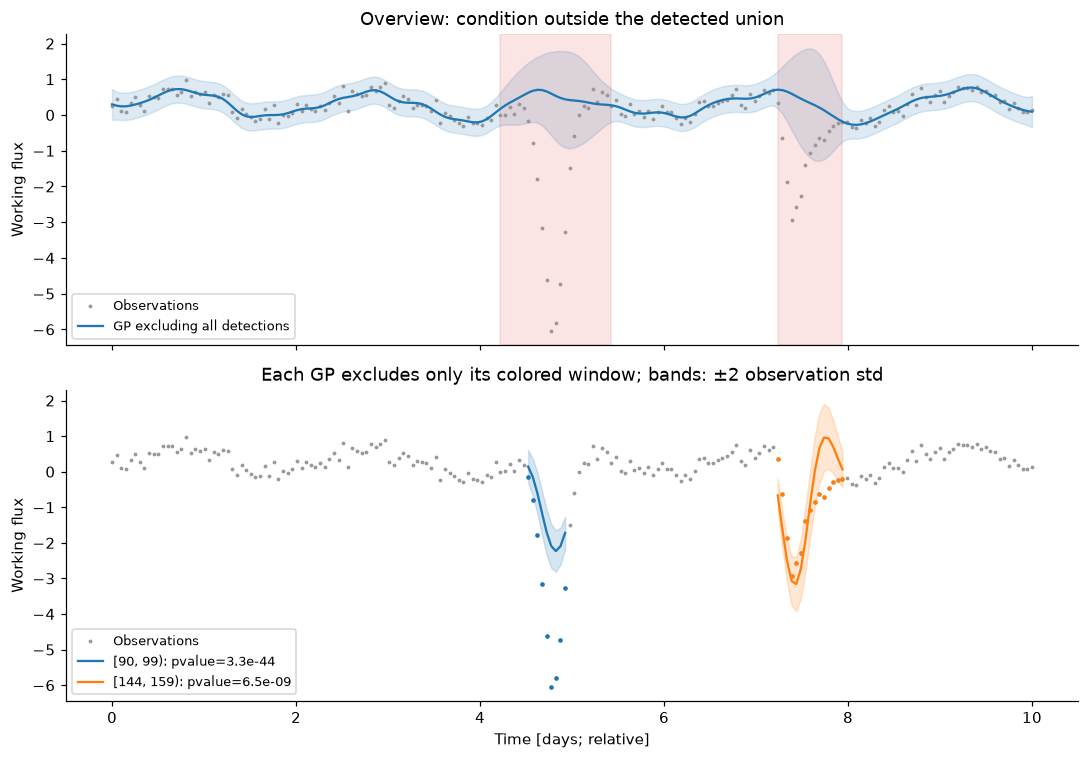

In [4]:
# Recreate the same observations and preserve an injection-free control.
clean = Nahiku.from_synthetic_noise(
    duration=10, n_points=200, period=2, amplitude=0.3,
    white_noise=0.02, red_noise=0, seed=48,
)
prewhitened = clean.copy()
prewhitened.inject_anomaly(center=4.8, width=0.12, depth=0.8, shape="gaussian")
prewhitened.inject_anomaly(center=7.4, width=0.07, depth=0.45, shape="exocomet")
injected_profile = prewhitened.flux - clean.flux

# Remove significant sinusoids using the default Balmung method.
pw_settings = dict(fmin=0.1, fmax=2, max_components=3, minimum_snr=4)
pw = prewhitened.prewhiten(**pw_settings)
clean.prewhiten(**pw_settings)
print("Removed frequencies [cycles/day]:", pw.frequencies)

# Measure dip attenuation before standardization using the paired control.
deepest = injected_profile.argmin()
recovered_profile = prewhitened.flux - clean.flux
print("Deepest-sample retained fraction:",
      recovered_profile[deepest] / injected_profile[deepest])

# Fit with the same GP configuration; learned parameters can change.
prewhitened.standardize().fit_gp(period=2, length_scale=4, iterations=120)
pw_greedy = prewhitened.greedy_search(
    sigma=4, grow_sigma=2, seed_statistic="loo", growth="threshold",
    direction="negative", gap_factor=5, max_events=20, backend="numpy",
)
pw_exhaustive = prewhitened.exhaustive_search(
    min_points=3, max_points=16, step=3, size_step=3, threshold=1e-8,
)

# Compare event recovery and inspect the remaining exhaustive detections.
for result in (pw_greedy, pw_exhaustive):
    print(result.method, result.intervals)
    print(prewhitened.evaluate(result))
pw_exhaustive.plot();

## Interpret the result

Both searches use the same observations and fitted GP, but apply different selection rules. Greedy search starts from negative leave-one-out deviations above `sigma=4` and grows intervals using `grow_sigma=2`. Exhaustive search tests its configured interval grid and selects windows using a p-value cutoff of `1e-8`. These thresholds are not equivalent significance levels, and raw metric values should not be compared across algorithms.

Greedy search recovers both injected events without additional detections (precision and recall both 1.0). Exhaustive search recovers both injections but also selects three additional events (precision 0.4, recall 1.0). These results apply to this light curve and configuration. They are insufficient to rank the algorithms in general.

The methods condition on different subsets of observations. This greedy configuration seeds detections from individual leave-one-out residuals and removes accepted intervals as it proceeds. Exhaustive search independently excludes an entire candidate window while retaining anomalies elsewhere in the light curve. The quasi-periodic GP can propagate structure associated with those retained anomalies into its prediction for the held-out window. A broad window also provides less local conditioning information than an individual leave-one-out sample. This can create strong disagreement in regions that are not injected events, even when greedy residual seeds do not flag them. The conditional prediction panels show the resulting disagreement. Period-related alignment can amplify it, but this example does not establish exact phase alignment or isolate a single cause.

After Balmung prewhitening over 0.1–2 cycles/day, one component at approximately 0.4966 cycles/day is removed. Both searches recover the two injected events without additional detections; the three extra exhaustive events are absent. The GP configuration and search thresholds are unchanged, but standardization and learned GP parameters change. This result supports prewhitening for this example. It does not establish that prewhitening removes false detections in general.

Prewhitening can also absorb part of a dip. Comparing independently prewhitened injected and injection-free series, the deepest injected sample retains about 95.6% of its amplitude. This paired-control measurement is specific to this simulation and does not establish preservation of every event's shape or depth.

The shaded regions show detected intervals; the printed reports compare them with the injected events. Event-level recovery measures overlap with the truth and does not establish precise event boundaries. Each result stores its own predictions and detections, so running exhaustive search does not overwrite the greedy result. Their overview predictions can differ because they condition on different retained observations. The conditional panels show the individual windows used to compute exhaustive scores.

This example explicitly uses NumPy/SciPy conditioning for greedy search and the default Torch conditioning for exhaustive search. Both implement the same conditional Gaussian calculations for fixed hyperparameters, up to numerical precision. This example compares detections; it does not benchmark backend runtimes.

Conditional p-values are not corrected for overlapping searches or parameter estimation. Before applying either method to a survey, calibrate thresholds on representative noise-only simulations and evaluate recovery across a range of injected widths and depths.

Consult the API reference for parameter and return-value details.